# 03 - Evaluation and fair comparison  (RUN ON: DGX, or any machine that has the trained runs)

Evaluates both models on the **same** validation and test data: accuracy, precision, recall, F1, confusion matrices,
95 % confidence intervals, McNemar test, size/speed, and a PASS/FAIL check against the proposal targets
(accuracy >= 90 %, macro-F1 > 0.85). The test split is used here for the first time.

**Primary** test view = one original image per source photo (independent samples). **Secondary** = all test images
including the dataset's pre-augmented copies.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

In [2]:
# ===== SETUP - run this cell first =====
import os, subprocess, sys
from pathlib import Path

# Colab only: put your GitHub repo URL here, OR leave "" and upload + unzip the project zip to /content
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
PROJECT_DIR = Path("/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone")
ZIP = Path("/content/fresh-rotten-fruit-capstone.zip")      # Colab: the project zip you uploaded to the Files panel
if not (PROJECT_DIR / "src").exists() and ZIP.exists():
    import shutil; shutil.unpack_archive(str(ZIP), "/content")
if not (PROJECT_DIR / "src").exists():
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    else:
        raise SystemExit(f"Project folder not found: {PROJECT_DIR}. Upload fresh-rotten-fruit-capstone.zip to /content (Files panel) or set REPO_URL above, then re-run.")
if IN_COLAB and os.getenv("FRUIT_SKIP_PIP") != "1":
    # Colab already has TensorFlow/pandas/scikit-learn; only the extras are installed (never reinstall TensorFlow).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_DIR / "requirements-colab.txt")], check=True)
sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)

from fruitfresh import config
print("Project:", PROJECT_DIR, "| split dir:", config.DEFAULT_SPLIT_DIR, "| work dir:", config.DEFAULT_WORK_DIR)

Project: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone | split dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/splits | work dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/workspace


In [3]:
import json, pandas as pd, matplotlib.pyplot as plt
from fruitfresh import compare as C
from fruitfresh.data_index import get_dataset_root
from fruitfresh.evaluate import evaluate_run, plot_confusion_matrix
from fruitfresh.splits import load_split
from fruitfresh.train import run_dir_for

DATA_ROOT = get_dataset_root(); WORK_DIR = config.DEFAULT_WORK_DIR; RESULTS = config.DEFAULT_RESULTS_DIR; SEED = config.SEED
RUNS = ["baseline_cnn", "mobilenet_v2"]          # or the best experiment runs (results/best_*.json)
train_df, val_df, test_df = load_split(config.DEFAULT_SPLIT_DIR)
N_BOOT = 2000

I0000 00:00:1792933362.274134  187330 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792933362.521819  187330 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792933372.276188  187330 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Evaluate (cached: re-running is instant)

In [6]:
results = {
    r: evaluate_run(
        run_dir_for(WORK_DIR, r, SEED),
        r,
        {"validation": val_df, "test": test_df},
        DATA_ROOT,
        n_boot=200,
        batch_size=16,
    )
    for r in RUNS
}

print("evaluated:", list(results))

evaluated: ['baseline_cnn', 'mobilenet_v2']


## 2. Main results

In [7]:
display(C.metric_table(results, "test_original"))
display(C.metric_table(results, "test_full"))

,model,images,source photos,accuracy [95% CI],macro precision,macro recall,macro F1 [95% CI]
0,baseline_cnn,215,215,"0.753 [0.693, 0.805]",0.758,0.752,"0.746 [0.682, 0.795]"
1,mobilenet_v2,215,215,"0.935 [0.898, 0.967]",0.941,0.920,"0.928 [0.886, 0.965]"


,model,images,source photos,accuracy [95% CI],macro precision,macro recall,macro F1 [95% CI]
0,baseline_cnn,1935,215,"0.774 [0.721, 0.823]",0.774,0.770,"0.765 [0.704, 0.816]"
1,mobilenet_v2,1935,215,"0.918 [0.886, 0.946]",0.924,0.898,"0.908 [0.868, 0.938]"


In [8]:
display(C.per_class_table(results, "test_original", "f1"))
display(C.per_class_table(results, "test_original", "recall"))

,baseline_cnn,mobilenet_v2
freshapples,0.753,0.925
freshbanana,0.857,0.958
freshoranges,0.704,0.931
rottenapples,0.760,0.943
rottenbanana,0.848,0.962
rottenoranges,0.552,0.851


,baseline_cnn,mobilenet_v2
freshapples,0.906,0.969
freshbanana,0.840,0.920
freshoranges,0.613,0.871
rottenapples,0.731,0.962
rottenbanana,0.780,1.000
rottenoranges,0.640,0.800


## 3. Targets from the proposal (checked against the real numbers)

In [9]:
display(C.targets_table(results))

,model,view,accuracy (target >= 90%),macro-F1 (target > 0.85),result
0,baseline_cnn,"test (originals only, PRIMARY)",0.753,0.746,FAIL
1,baseline_cnn,test (all images),0.774,0.765,FAIL
2,mobilenet_v2,"test (originals only, PRIMARY)",0.935,0.928,PASS
3,mobilenet_v2,test (all images),0.918,0.908,PASS


## 4. Confusion matrices

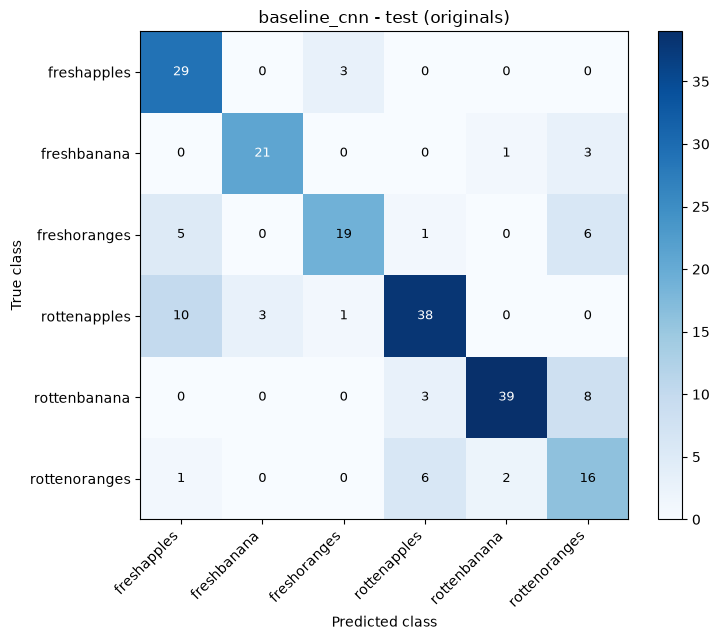

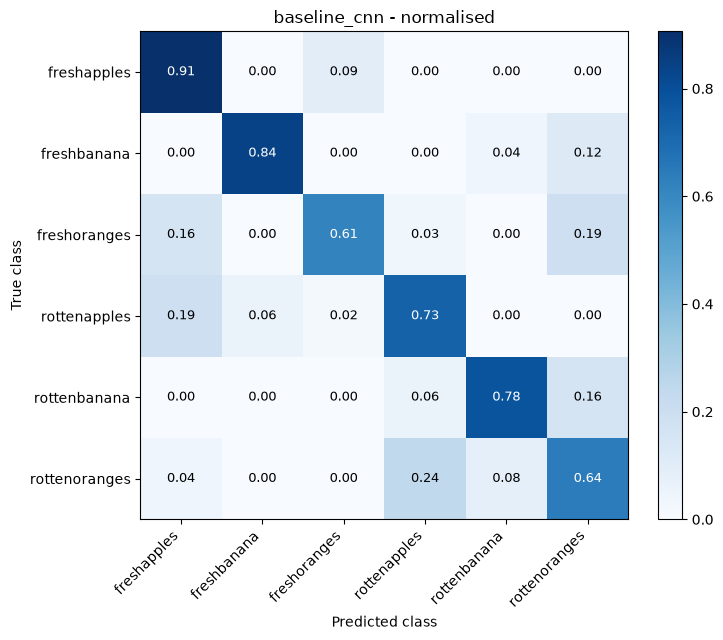

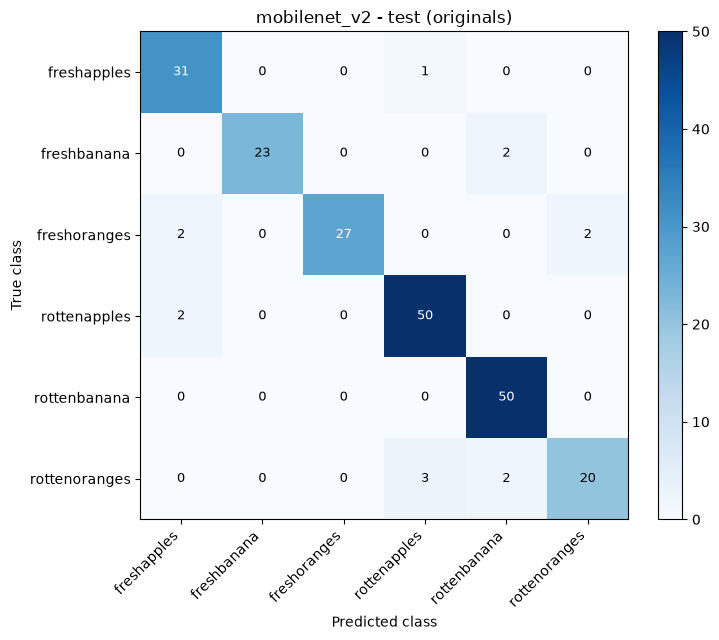

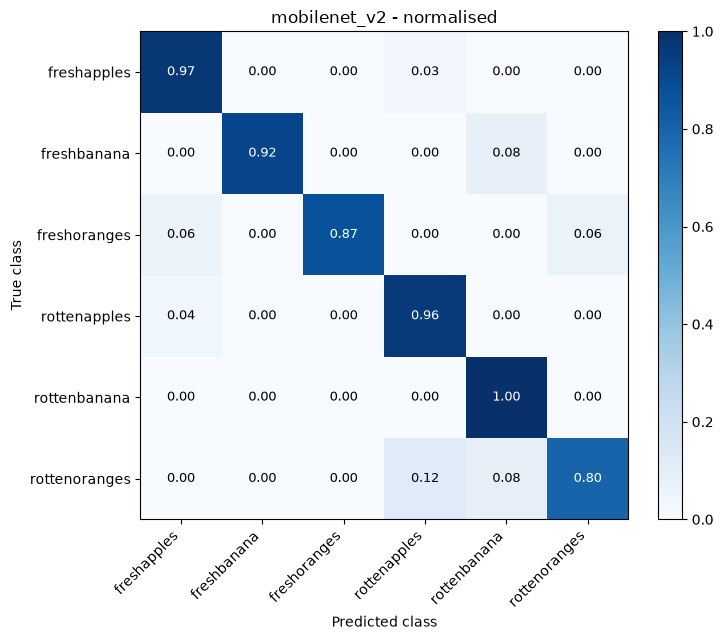

In [10]:
for r in RUNS:
    plot_confusion_matrix(results[r]["test_original"]["confusion_matrix"], title=f"{r} - test (originals)"); plt.show()
    plot_confusion_matrix(results[r]["test_original"]["confusion_matrix"], title=f"{r} - normalised", normalize=True); plt.show()

## 5. Fairness evidence, significance and efficiency

In [11]:
display(C.fairness_table(WORK_DIR, RUNS, SEED))
mc = C.mcnemar_between(WORK_DIR, RUNS[0], RUNS[1], SEED)
print(mc, "-> a p-value above 0.05 means the difference between the two models could be chance")
eff = C.efficiency_table(WORK_DIR, RUNS, SEED); display(eff)
final = C.select_final_model(results, eff); print(final)

,baseline_cnn,mobilenet_v2
split (same CSV files),see split_manifest.json,see split_manifest.json
seed,42,42
input size,224x224,224x224
training augmentation,True,True
class weights,True,True
loss / optimizer,sparse categorical cross-entropy / Adam,sparse categorical cross-entropy / Adam
train / val images,8280 / 1782,8280 / 1782
pretrained (ImageNet),True,True
epochs run,10,23
hardware,"1 x GPU, global batch 2, off","1 x GPU, global batch 2, off"


{'a_only_correct': 6, 'b_only_correct': 45, 'p_value': 1.8323628836469652e-08} -> a p-value above 0.05 means the difference between the two models could be chance


,model,params (M),file size (MB),"latency (ms/image, batch 1)",training time (min)
0,baseline_cnn,1.18,14.2,51.0,7.7
1,mobilenet_v2,2.27,23.0,184.1,17.3


{'final_model': 'mobilenet_v2', 'reason': 'highest validation macro-F1', 'validation_macro_f1': {'baseline_cnn': 0.8418469568607015, 'mobilenet_v2': 0.996130474868716}}


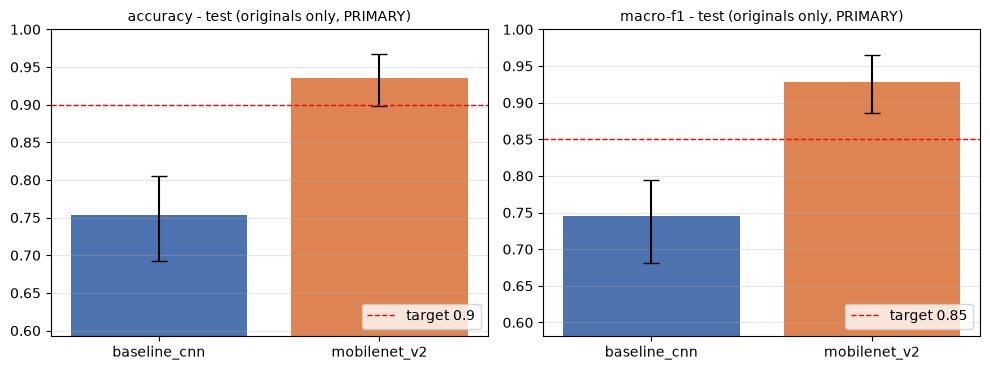

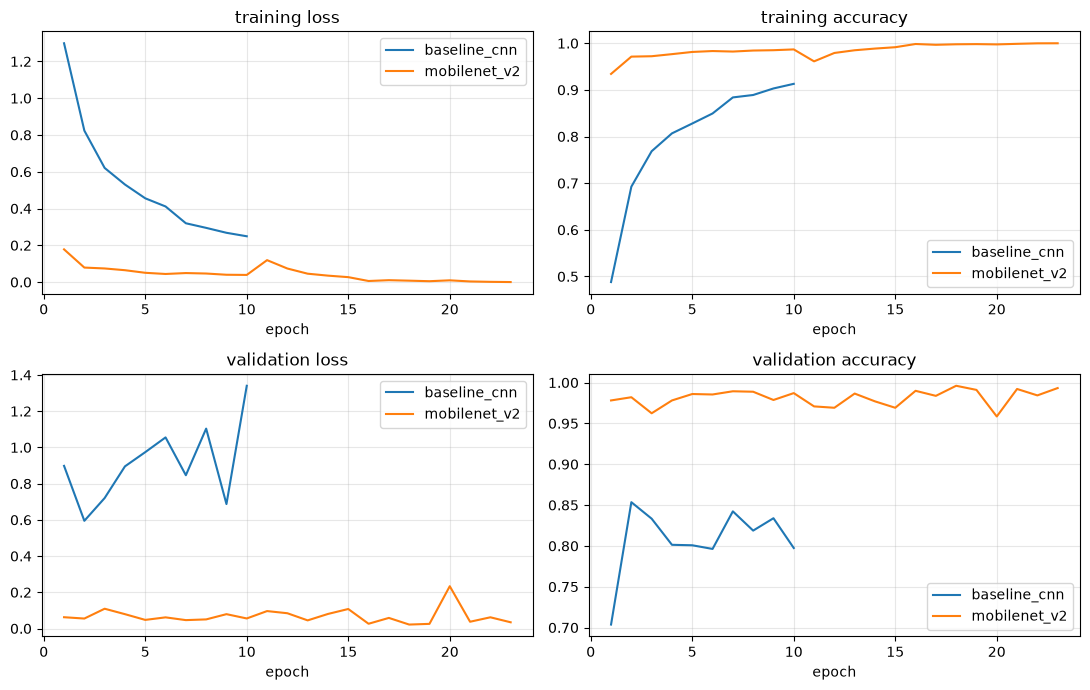

In [12]:
C.plot_metric_bars(results, "test_original"); plt.show()
from fruitfresh.plots import plot_training_curves
plot_training_curves({r: run_dir_for(WORK_DIR, r, SEED) / "history.csv" for r in RUNS}); plt.show()

## 6. Robustness: accuracy per kind of test image

In [13]:
display(pd.DataFrame({r: {k: v["accuracy"] for k, v in results[r]["test_full"]["by_augmentation"].items()} for r in RUNS}).round(3))

,baseline_cnn,mobilenet_v2
original,0.753,0.935
rotated,0.785,0.915
saltandpepper,0.758,0.879
translation,0.753,0.935
vertical_flip,0.772,0.935


## 7. Save the report and the final-model choice

In [14]:
RESULTS.mkdir(exist_ok=True)
C.write_comparison_report(results, WORK_DIR, RUNS, SEED, RESULTS / "comparison_report.md")
(RESULTS / "final_model.json").write_text(json.dumps(final, indent=2))
C.metric_table(results, "test_original").to_csv(RESULTS / "metrics_test_original.csv", index=False)
print("written:", sorted(p.name for p in RESULTS.iterdir()))

written: ['.gitkeep', 'comparison_report.md', 'final_model.json', 'metrics_test_original.csv']
